In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mukaberayvonne/lab2-dataset/Country Schools.csv



# Lab 2: Country Schools Data Analysis

## 1. Introduction

This lab focuses on basic data preprocessing and the application of two Computing Intelligence techniques: anomaly detection and cluster analysis. The Country Schools dataset will be used to identify unusual records and group schools with similar characteristics.


In [2]:
import pandas as pd
#Loading country schools dataset
schoolsData=pd.read_csv("/kaggle/input/datasets/mukaberayvonne/lab2-dataset/Country Schools.csv")
print("Dataset loaded successfully:", schoolsData.shape)

Dataset loaded successfully: (50, 8)


In [3]:
#First five records
schoolsData.head()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [4]:
#last five records
schoolsData.tail()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
45,EMBU,381.0,248.0,133.0,65.09%,8438.0,496.0,46
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50



## 2. Data Inspection

In this section, i will inspect the Country Schools dataset to understand its structure, identify the data types of its columns, and determine the number of records and features available for analysis.


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,InstalledLDDs,InstalledTDDs,FID
count,48.00,48.00,48.00,48.00,48.00,50.00
mean,905.38,609.54,295.83,30150.75,1219.08,25.50
std,3079.87,2078.97,1009.29,102851.95,4157.94,14.58
min,93.00,8.00,4.00,606.00,16.00,1.00
25%,271.75,161.25,53.25,6289.00,322.50,13.25
50%,422.50,314.50,130.50,14165.00,629.00,25.50
75%,637.00,420.25,247.75,23215.00,840.50,37.75
max,21729.00,14629.00,7100.00,723618.00,29258.00,50.00


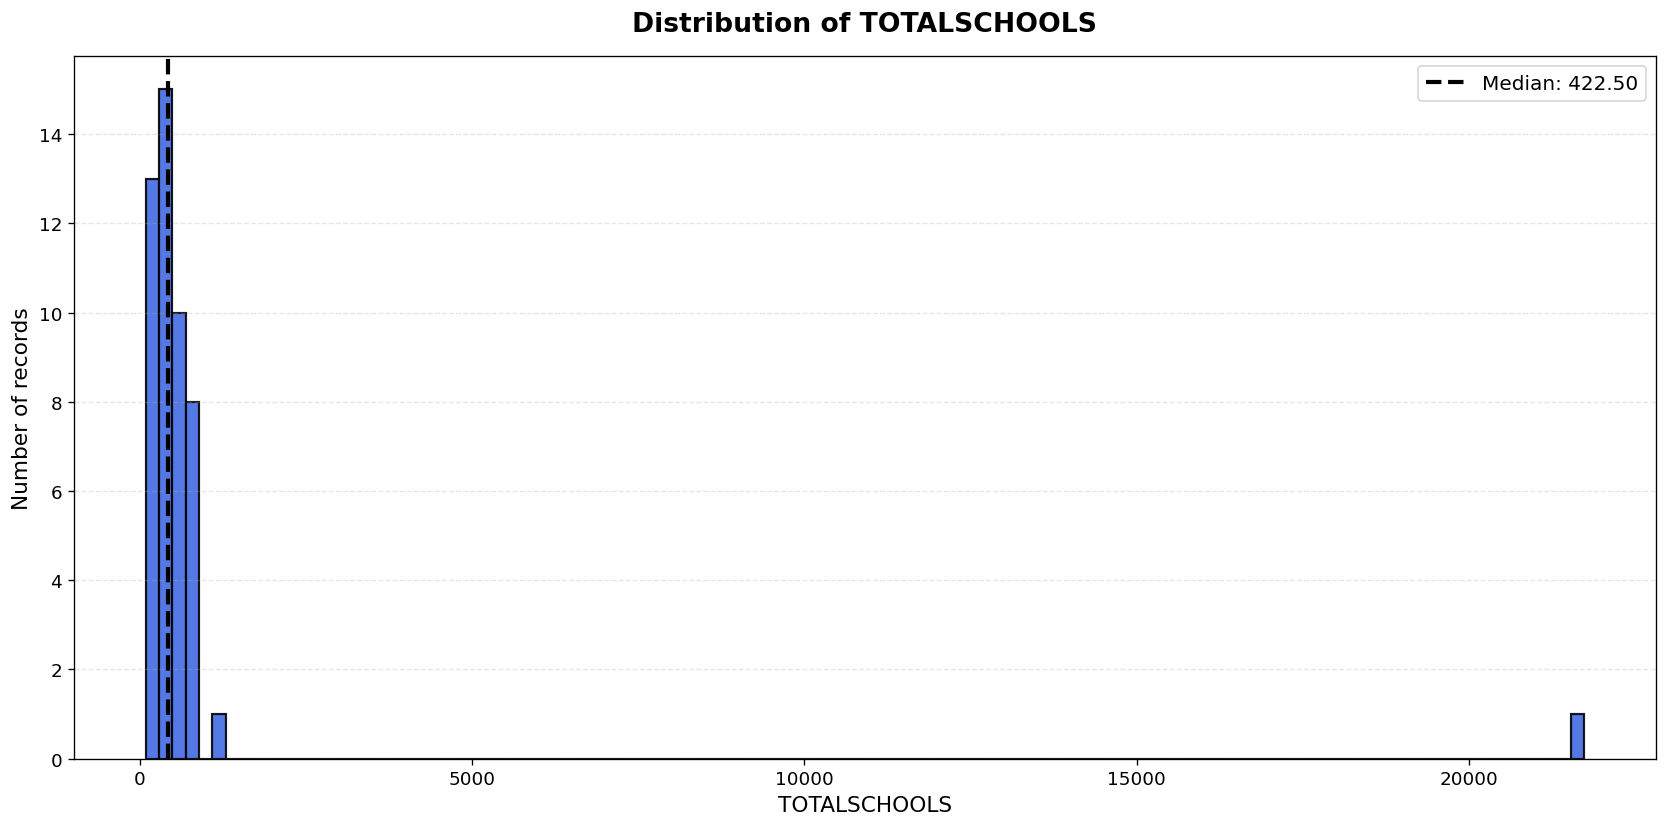

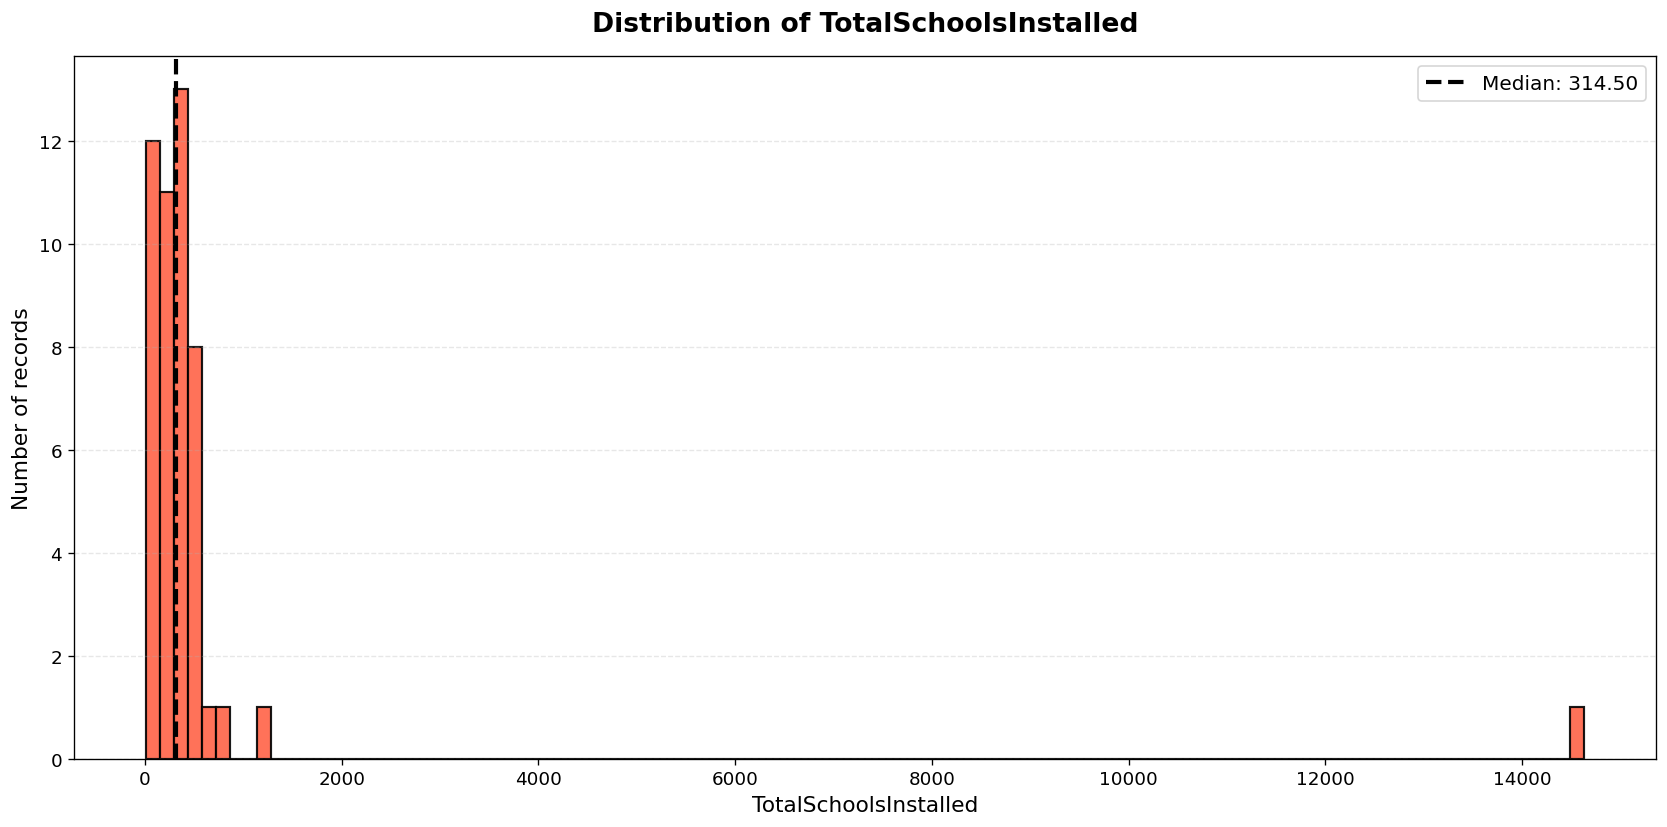

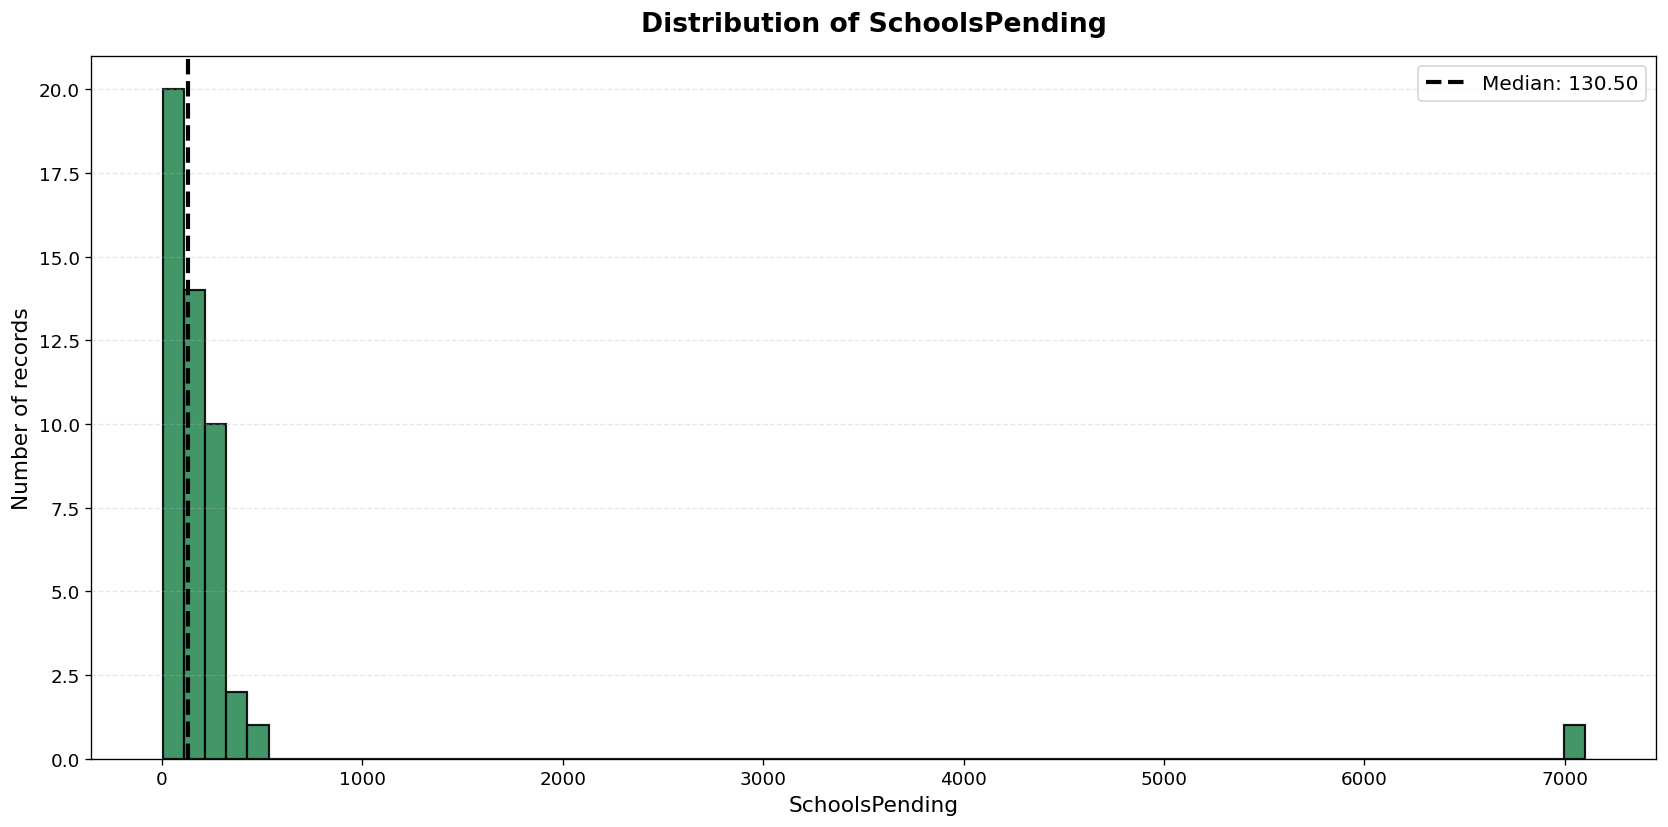

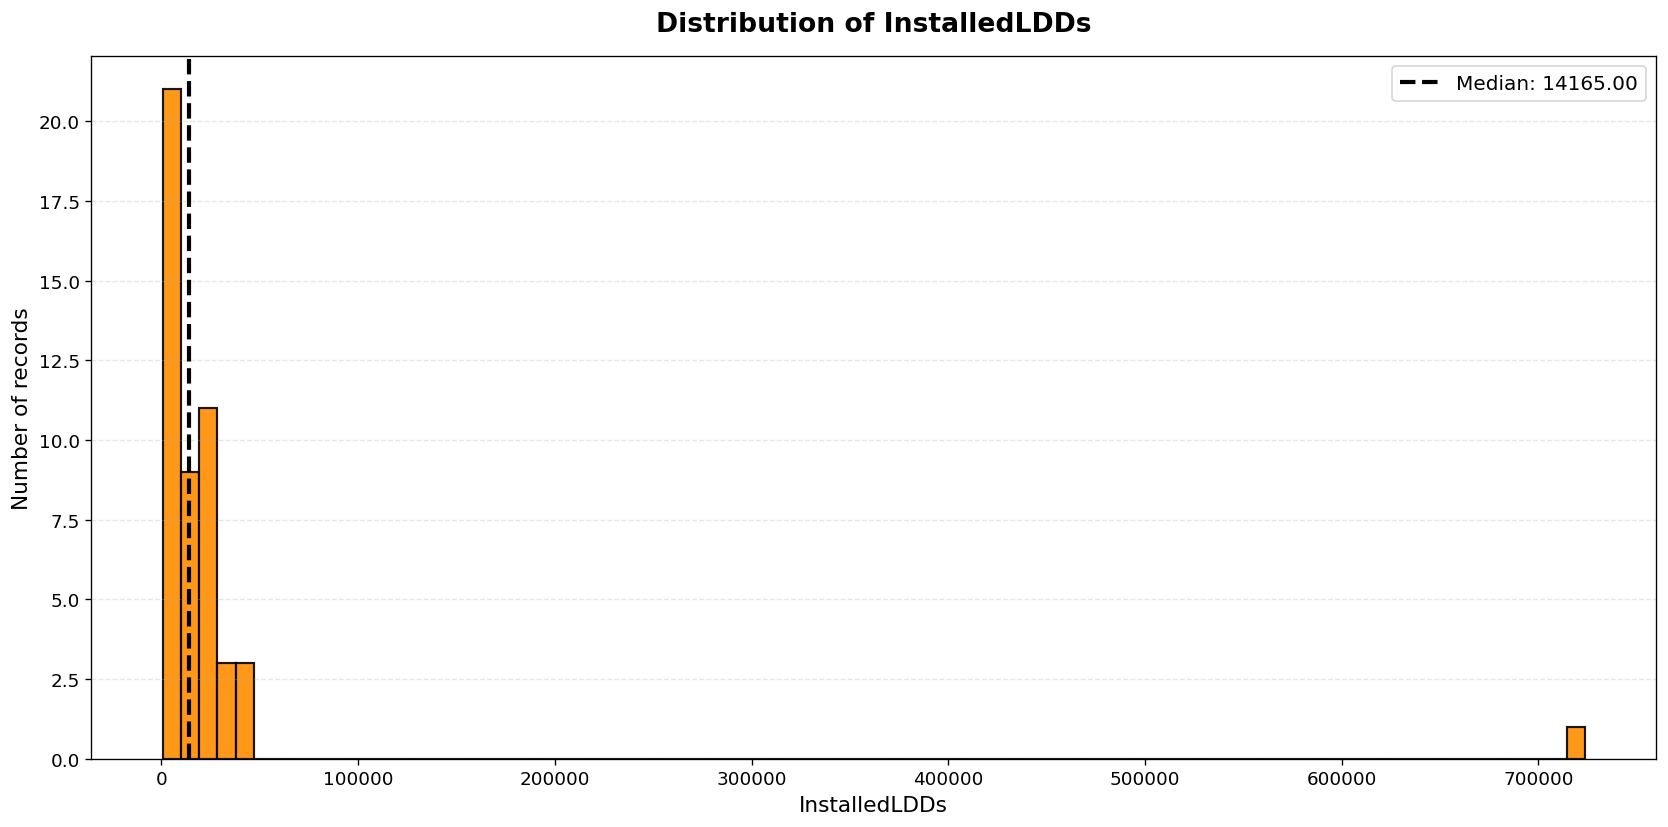

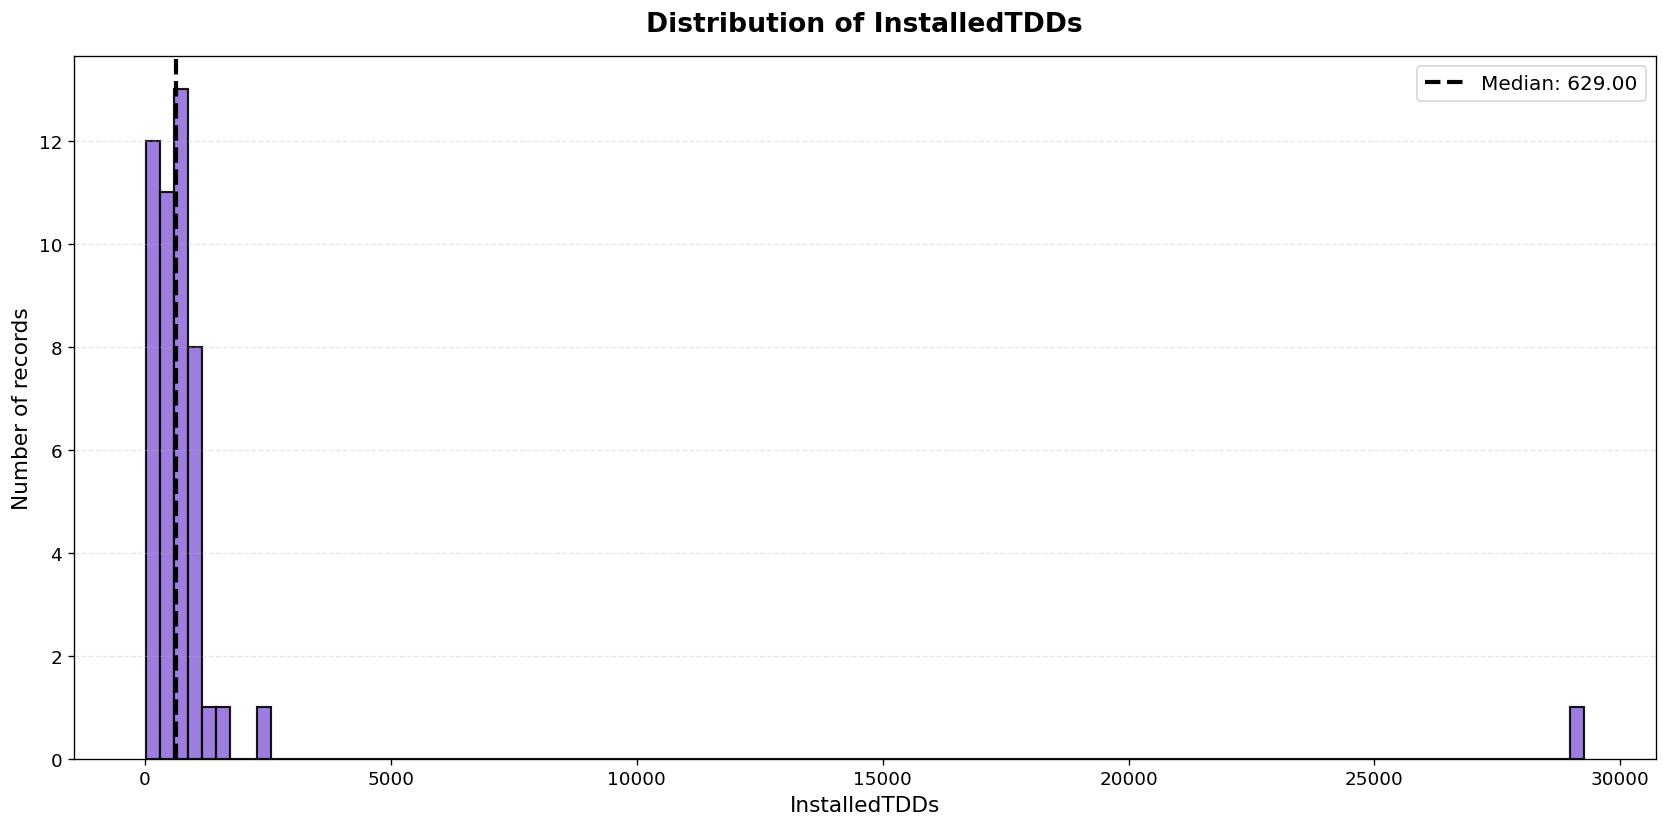

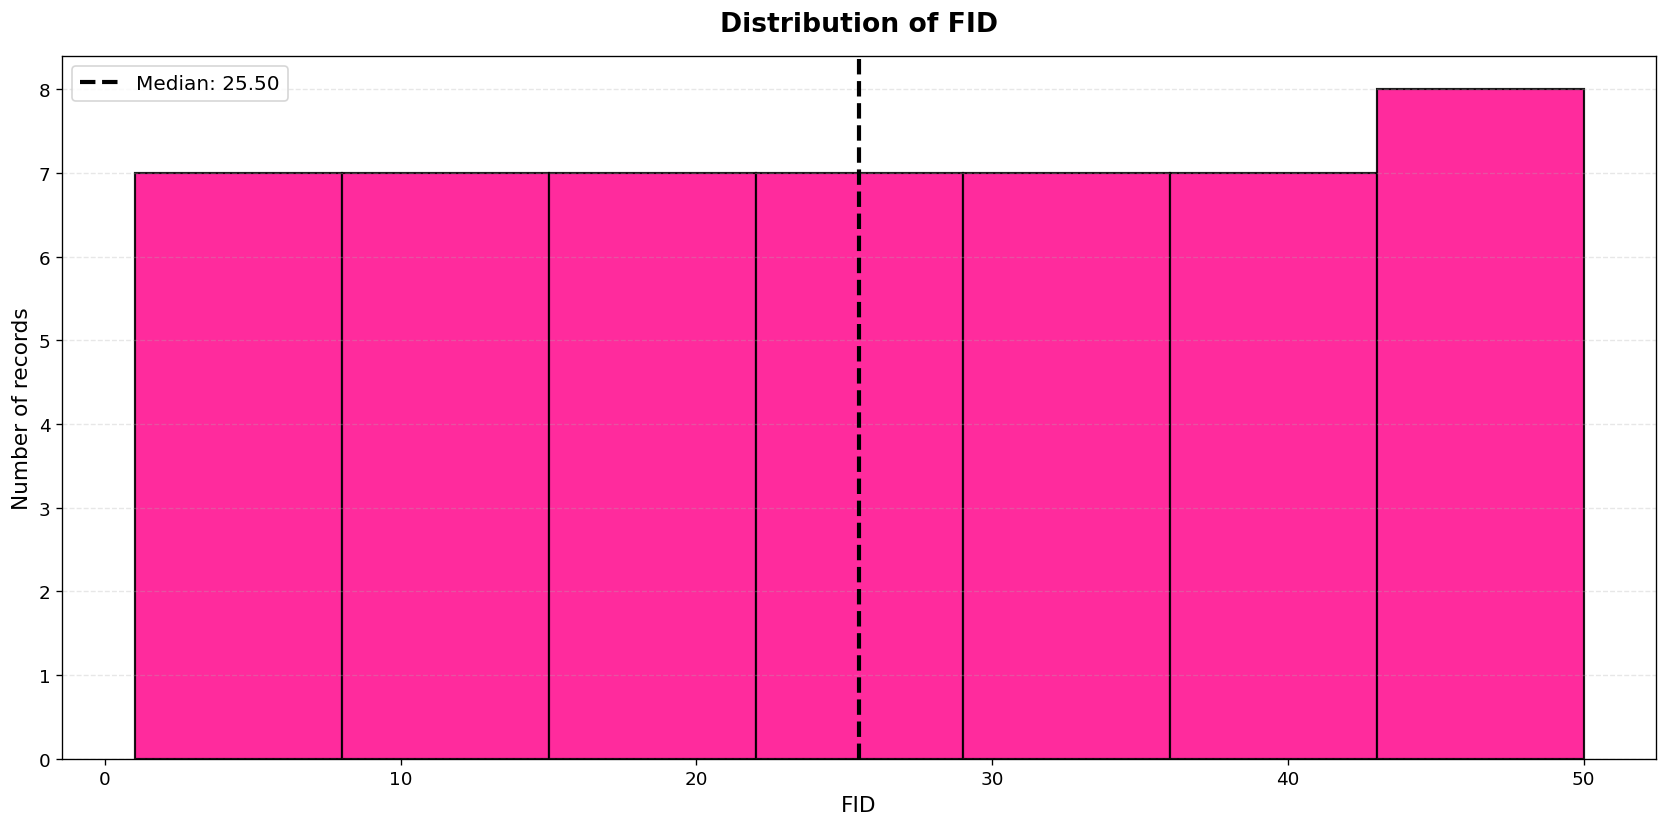

In [5]:
import matplotlib.pyplot as plt

numericalData = schoolsData.select_dtypes(include="number")

#Numerical summary
display(numericalData.describe().round(2))

colors = [
    "royalblue", "tomato", "seagreen", "darkorange",
    "mediumpurple", "deeppink", "teal", "gold",
    "slateblue", "coral"
]

# Displaying on histogram 
for i, column in enumerate(numericalData.columns):
    values = numericalData[column].dropna()

    fig, ax = plt.subplots(figsize=(14, 7), dpi=120)

    ax.hist(
        values,
        bins="auto",
        color=colors[i % len(colors)],
        edgecolor="black",
        linewidth=1.3,
        alpha=0.9
    )

    ax.axvline(
        values.median(),
        color="black",
        linestyle="--",
        linewidth=2.5,
        label=f"Median: {values.median():.2f}"
    )

    ax.set_title(
        f"Distribution of {column}",
        fontsize=16,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel(column, fontsize=13)
    ax.set_ylabel("Number of records", fontsize=13)
    ax.tick_params(axis="both", labelsize=11)
    ax.legend(fontsize=12)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


## 3. Data Preprocessing

### 3.1 Checking Missing Values and Duplicate Records

In this step, i will check the dataset for missing values and duplicate records. This helps us identify data quality issues before applying anomaly detection and cluster analysis.


In [6]:
# Count missing values in each column
print("Missing values per column:")
display(schoolsData.isna().sum().to_frame(name="Missing Values"))

# Calculate the total number of missing values
print("Total missing values:", schoolsData.isna().sum().sum())

# Count duplicate records
print("\nNumber of duplicate rows:", schoolsData.duplicated().sum())

Missing values per column:


,Missing Values
SNO,2
TOTALSCHOOLS,2
TotalSchoolsInstalled,2
SchoolsPending,2
PercentageInstalled,2
InstalledLDDs,2
InstalledTDDs,2
FID,0


Total missing values: 14

Number of duplicate rows: 0



### 3.2 Handling Missing Values(Data Cleaning)

The dataset contains 14 missing values across seven columns, with two missing values in each column. No duplicate records were found. In this step, I will remove records that contain missing values to prepare a complete dataset for further analysis.


In [7]:

# Remove rows containing missing values
schoolsData = schoolsData.dropna().copy()

# Verify the cleaned dataset
print("\nMissing values after cleaning:")
display(schoolsData.isnull().sum())

print("Dataset shape after cleaning:", schoolsData.shape)

display(schoolsData.head())



Missing values after cleaning:


SNO                      0
TOTALSCHOOLS             0
TotalSchoolsInstalled    0
SchoolsPending           0
PercentageInstalled      0
InstalledLDDs            0
InstalledTDDs            0
FID                      0
dtype: int64

Dataset shape after cleaning: (48, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


#### Checking Feature Data Types

Before scaling the selected features, we will inspect their data types and sample values to identify any columns containing non-numeric data.

In [8]:

# Select the numerical features
featureColumns = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

# Check the data types of the selected features
print("Feature data types:")
display(schoolsData[featureColumns].dtypes.to_frame(name="Data Type"))

# Display sample values
print("Sample values:")
display(schoolsData[featureColumns].head())

# Check for non-numeric values
print("Non-numeric values:")
for column in featureColumns:
    nonNumeric = pd.to_numeric(schoolsData[column], errors="coerce").isna().sum()
    print(f"{column}: {nonNumeric}")


Feature data types:


,Data Type
TOTALSCHOOLS,float64
TotalSchoolsInstalled,float64
SchoolsPending,float64
PercentageInstalled,object
InstalledLDDs,float64
InstalledTDDs,float64


Sample values:


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,358.0,37.0,321.0,10.34%,3744.0,74.0
1,875.0,552.0,323.0,63.09%,22982.0,1104.0
2,498.0,242.0,256.0,48.59%,15114.0,484.0
3,1238.0,1200.0,38.0,96.93%,42162.0,2400.0
4,159.0,143.0,16.0,89.94%,7415.0,286.0


Non-numeric values:
TOTALSCHOOLS: 0
TotalSchoolsInstalled: 0
SchoolsPending: 0
PercentageInstalled: 48
InstalledLDDs: 0
InstalledTDDs: 0


#### Converting Percentage Values

The `PercentageInstalled` column contains percentage signs, causing it to be stored as text. We will remove the signs and convert the column to a numerical data type so it can be used in anomaly detection and cluster analysis.

In [9]:

from sklearn.preprocessing import StandardScaler

# Remove percentage signs and convert values to numbers
schoolsData["PercentageInstalled"] = pd.to_numeric(
    schoolsData["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False),
    errors="raise"
)

# Select the features for analysis
schoolsFeatures = schoolsData[featureColumns].copy()

# Standardize the selected features
scaler = StandardScaler()
schoolsScaled = scaler.fit_transform(schoolsFeatures)

# Display data types and shapes
print("Data types:")
print(schoolsFeatures.dtypes)

print("\nOriginal feature shape:", schoolsFeatures.shape)
print("Scaled feature shape:", schoolsScaled.shape)

# Display the scaled feature values
display(
    pd.DataFrame(schoolsScaled, columns=featureColumns)
    .head()
    .round(2)
)


Data types:
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled      float64
InstalledLDDs            float64
InstalledTDDs            float64
dtype: object

Original feature shape: (48, 6)
Scaled feature shape: (48, 6)


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,-0.18,-0.28,0.03,-2.12,-0.26,-0.28
1,-0.01,-0.03,0.03,-0.04,-0.07,-0.03
2,-0.13,-0.18,-0.04,-0.61,-0.15,-0.18
3,0.11,0.29,-0.26,1.30,0.12,0.29
4,-0.24,-0.23,-0.28,1.03,-0.22,-0.23


## 4. Anomaly Detection

Anomaly detection identifies records that differ substantially from the general pattern in the dataset. In this experiment, we use the Isolation Forest algorithm to identify potentially unusual school statistics based on the six selected numerical features.

In [10]:
from sklearn.ensemble import IsolationForest

# Create and train the anomaly detection model
anomalyModel = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

# Identify normal records and potential anomalies
anomalyLabels = anomalyModel.fit_predict(schoolsScaled)

# Add results to a copy of the cleaned dataset
anomalyResults = schoolsData.copy()
anomalyResults["AnomalyStatus"] = anomalyLabels

# Summarize the results
print("Anomaly detection results:")
print("Normal records:", (anomalyLabels == 1).sum())
print("Potential anomalies:", (anomalyLabels == -1).sum())

# Display records flagged as potential anomalies
display(
    anomalyResults[anomalyResults["AnomalyStatus"] == -1]
)

Anomaly detection results:
Normal records: 41
Potential anomalies: 7


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID,AnomalyStatus
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1,-1
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4,-1
13,MAKUENI,887.0,833.0,54.0,93.91,30973.0,1666.0,14,-1
17,KAKAMEGA,880.0,572.0,308.0,65.00,44338.0,1144.0,18,-1
36,WAJIR,211.0,11.0,200.0,5.21,855.0,22.0,37,-1
38,MARSABIT,138.0,8.0,130.0,5.80,606.0,16.0,39,-1
47,TOTAL,21729.0,14629.0,7100.0,67.32,723618.0,29258.0,48,-1


### 4.1 Interpretation of Results

The Isolation Forest model classified 41 records as normal and flagged 7 as potential anomalies. This represents approximately 14.6% of the dataset. The flagged records include counties with low installation rates, counties with high installation rates, and a row representing the overall total. These records have unusual combinations of features compared with the rest of the dataset and may require further investigation. The results do not necessarily indicate incorrect data.

Anomaly detection results:
Anomaly
Normal               41
Potential Anomaly     7
Name: count, dtype: int64


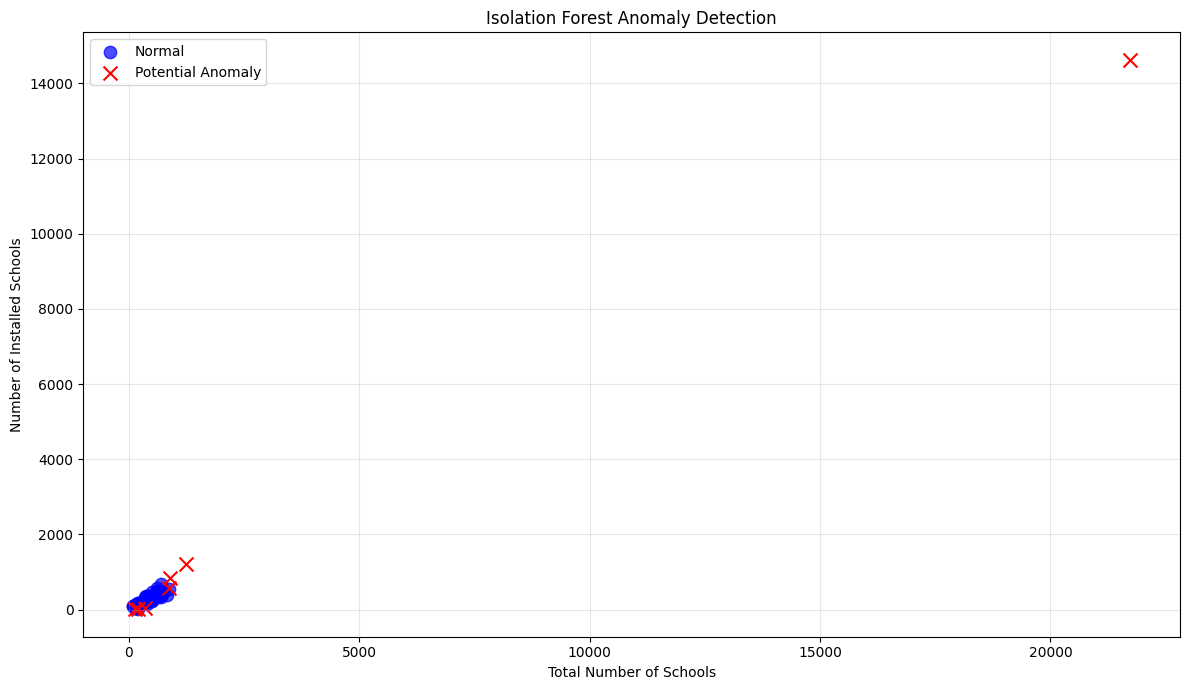

In [11]:

from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# Detect potential anomalies
isolationForest = IsolationForest(
    contamination="auto",
    random_state=42
)

anomalyResults = isolationForest.fit_predict(schoolsScaled)

# Store the detection results
schoolsData["Anomaly"] = anomalyResults

# Count normal records and potential anomalies
print("Anomaly detection results:")
print(schoolsData["Anomaly"].value_counts().rename({
    1: "Normal",
    -1: "Potential Anomaly"
}))

# Create the scatter plot
plt.figure(figsize=(12, 7))

plt.scatter(
    schoolsData.loc[schoolsData["Anomaly"] == 1, "TOTALSCHOOLS"],
    schoolsData.loc[schoolsData["Anomaly"] == 1, "TotalSchoolsInstalled"],
    color="blue",
    label="Normal",
    s=80,
    alpha=0.7
)

plt.scatter(
    schoolsData.loc[schoolsData["Anomaly"] == -1, "TOTALSCHOOLS"],
    schoolsData.loc[schoolsData["Anomaly"] == -1, "TotalSchoolsInstalled"],
    color="red",
    label="Potential Anomaly",
    s=100,
    marker="x"
)

plt.title("Isolation Forest Anomaly Detection")
plt.xlabel("Total Number of Schools")
plt.ylabel("Number of Installed Schools")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Cluster Analysis

Cluster analysis groups records with similar characteristics. In this experiment, we use the K-Means algorithm to group school records based on total schools, installation progress, pending schools, and installed LDDs and TDDs. The six features are standardized so differences in their numerical ranges do not dominate the clustering process.

In [12]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Keep individual counties only
countyMask = schoolsData["SNO"].astype(str).str.upper() != "TOTAL"
countyData = schoolsData.loc[countyMask].copy()

# Select the six numerical features
countyFeatures = countyData[featureColumns]

# Scale features using county records only
clusterScaler = StandardScaler()
countyScaled = clusterScaler.fit_transform(countyFeatures)

# Create and fit the K-Means model
kmeansModel = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

countyData["Cluster"] = kmeansModel.fit_predict(countyScaled)

# Show the number of counties in each cluster
print("Number of counties analyzed:", len(countyData))
print("\nCounties per cluster:")
display(
    countyData["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame(name="Number of Counties")
)

# Display county names and their assigned clusters
display(countyData[["SNO", "Cluster"]].sort_values("Cluster"))

Number of counties analyzed: 47

Counties per cluster:


,Number of Counties
Cluster,
0,16
1,17
2,14


,SNO,Cluster
1,HOMA BAY,0
3,KITUI,0
7,MIGORI,0
11,NANDI,0
13,MAKUENI,0
15,KISII,0
10,NAROK,0
16,KISUMU,0
19,BOMET,0
27,MERU,0


### 5.1 Interpretation of Cluster Groups

K-Means divided the 47 individual counties into three clusters. Cluster 0 contains 16 counties, Cluster 1 contains 17 counties, and Cluster 2 contains 14 counties. These cluster labels do not indicate a ranking. To understand the characteristics of each group, we will compare the average values of the selected school features.

In [13]:
clusterProfiles = (
    countyData.groupby("Cluster")[featureColumns]
    .mean()
    .round(2)
)

print("Average feature values by cluster:")
display(clusterProfiles)

Average feature values by cluster:


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
Cluster,,,,,,
0,742.62,542.56,200.06,72.69,27458.06,1085.12
1,309.94,244.65,65.29,80.36,12209.29,489.29
2,327.00,127.79,199.21,33.92,5480.79,255.57


### 5.2 Visualizing the Clusters

A bar chart will compare the average installation percentage across the three clusters. This helps show how installation progress differs between the groups.

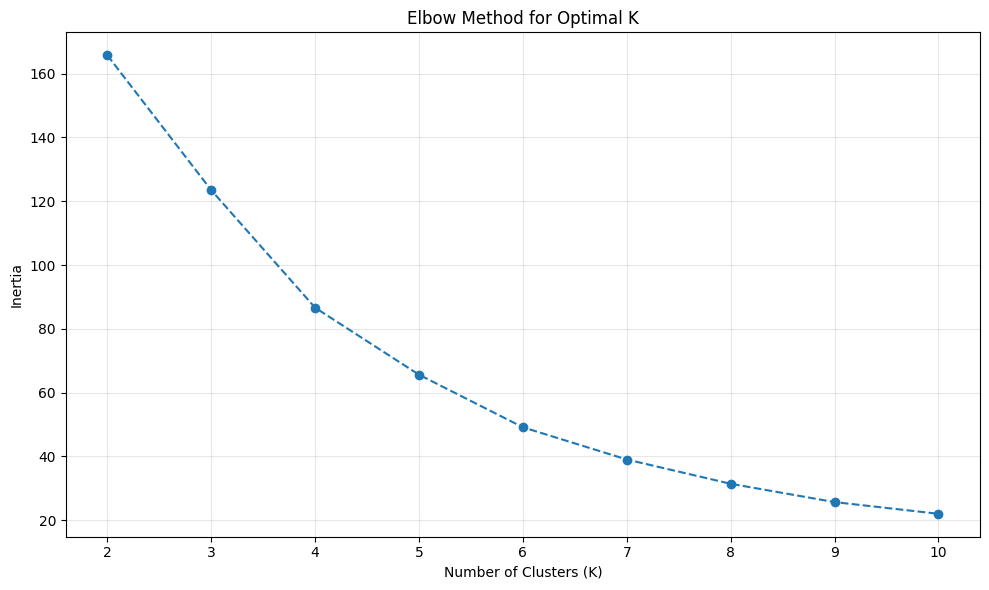

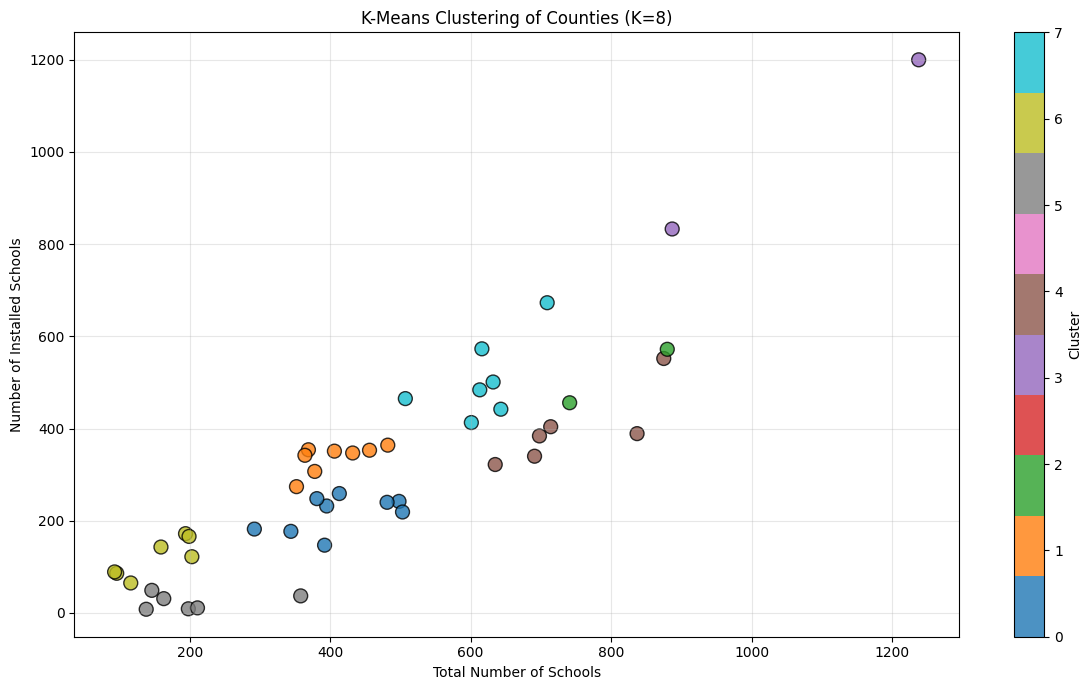

Number of counties in each cluster:


,Number of Counties
Cluster,
0,9
1,8
2,2
3,2
4,6
5,6
6,7
7,7


Average characteristics of each cluster:


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
Cluster,,,,,,
0,411.00,216.22,194.78,53.32,8248.33,432.44
1,404.88,336.50,68.38,83.58,18445.38,673.00
2,810.50,514.00,296.50,63.27,41541.00,1028.00
3,1062.50,1016.50,46.00,95.42,36567.50,2033.00
4,741.67,398.50,343.17,53.51,17257.50,797.00
5,202.33,24.17,178.17,13.08,1785.17,48.33
6,151.43,120.43,31.00,80.49,6010.71,240.86
7,617.29,507.29,110.00,82.19,27038.86,1014.57


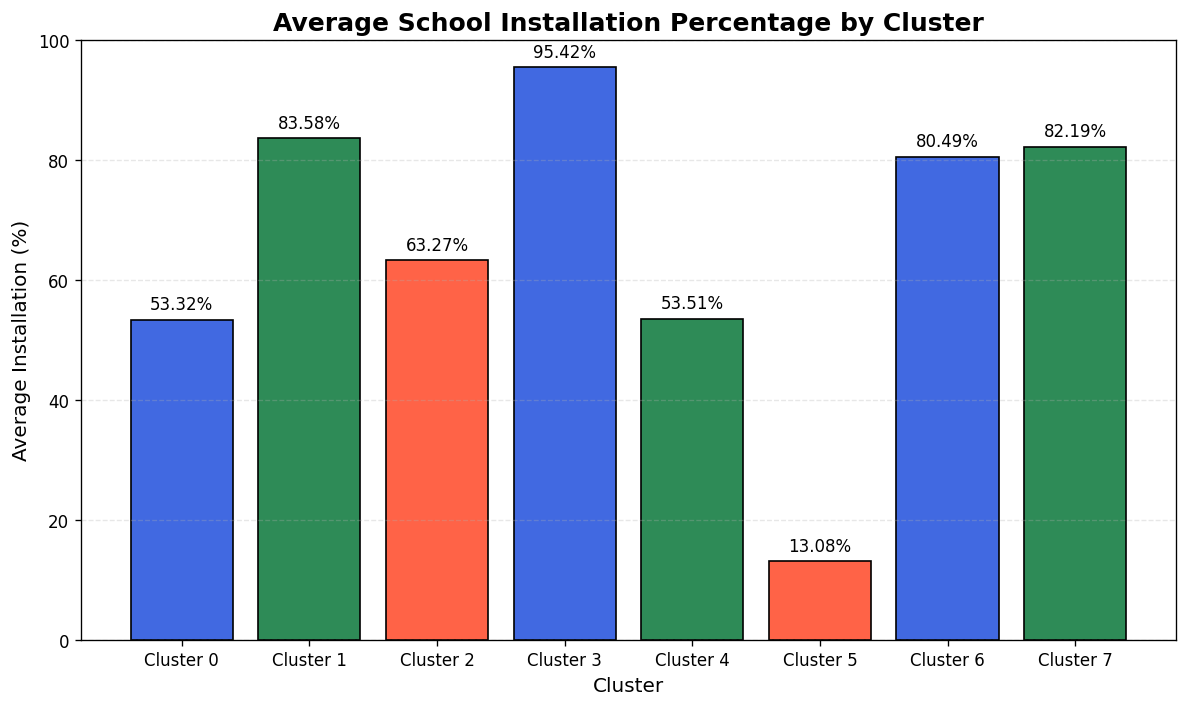

In [14]:

 
# CLUSTERING ANALYSIS USING K-MEANS
 

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Prepare the county data
# Exclude the aggregate TOTAL row
countyMask = schoolsData["SNO"].astype(str).str.upper() != "TOTAL"
countyData = schoolsData.loc[countyMask].copy()

# 2. Select numerical features for clustering
featureColumns = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

X = countyData[featureColumns]

# 3. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


 
# 4. ELBOW METHOD
 

inertiaValues = []
kValues = range(2, 11)

for k in kValues:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertiaValues.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(10, 6))

plt.plot(
    kValues,
    inertiaValues,
    marker="o",
    linestyle="--"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(kValues))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


 
# 5. APPLY K-MEANS CLUSTERING
 

# Use K = 8 to match the reference scatter plot
optimalK = 8

kmeans = KMeans(
    n_clusters=optimalK,
    random_state=42,
    n_init=10
)

countyData["Cluster"] = kmeans.fit_predict(X_scaled)

 
# 6. K-MEANS SCATTER PLOT
 

plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    countyData["TOTALSCHOOLS"],
    countyData["TotalSchoolsInstalled"],
    c=countyData["Cluster"],
    cmap="tab10",
    s=100,
    alpha=0.8,
    edgecolors="black"
)

plt.title("K-Means Clustering of Counties (K=8)")
plt.xlabel("Total Number of Schools")
plt.ylabel("Number of Installed Schools")

plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

 
# 7. DISPLAY NUMBER OF COUNTIES IN EACH CLUSTER
 

clusterCounts = countyData["Cluster"].value_counts().sort_index()

print("Number of counties in each cluster:")
display(clusterCounts.to_frame(name="Number of Counties"))


 
# 8. DISPLAY CLUSTER PROFILES
 

clusterProfiles = countyData.groupby("Cluster")[featureColumns].mean()

print("Average characteristics of each cluster:")
display(clusterProfiles.round(2))

#on histogram
clusterPercentages = clusterProfiles["PercentageInstalled"]

plt.figure(figsize=(10, 6), dpi=120)

bars = plt.bar(
    [f"Cluster {cluster}" for cluster in clusterPercentages.index],
    clusterPercentages.values,
    color=["royalblue", "seagreen", "tomato"],
    edgecolor="black"
)

plt.title("Average School Installation Percentage by Cluster",
          fontsize=15, fontweight="bold")
plt.xlabel("Cluster", fontsize=12)
plt.ylabel("Average Installation (%)", fontsize=12)
plt.ylim(0, 100)
plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Conclusion

This analysis helped identify unusual records in the dataset and group counties according to their school installation patterns. The K-Means results showed clear differences between counties, with some having made strong progress in school installation while others still have many schools pending installation. Overall, the findings provide a better understanding of the progress across counties and highlight areas that may need more attention.